# Fused (Image and Tabular) Model Evaluation

The image-only CNN performed well and from its results in `04_cnn_model.ipynb` suggests that the images carried more information than solely using age evident from the results of the age-band comparison. In this model, the image-only CNN configuration was retrained with added tabular features of the age and sex of the patient. The image-only model could have learned the age of the patient based on the scan of the patients brain. By fusing the feature types, the model will be given the patients' ages explicitly which could possibly improve model performance. 

Unlike in image-only model, there was no direct tuning for hyperparameters, the best configuration from the image-only model was used i.e. `[batch=8; lr=0.001; wd=0.01]`. 

In [1]:
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, brier_score_loss, roc_auc_score, 
                             roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

from src.cohort import build_cohort
from src.config import RESULTS
from src.metrics import OOF_PATH, stitch_folds, score_model, compare, bootstrap_ci, threshold_predictions

FUSED_DIR = RESULTS / "cnn_fused"
cohort = build_cohort(expected_n=617, verbose=False)

### Stitch folds and Score the Model

In [2]:
stitch_folds(FUSED_DIR, "fused_cnn_prob", cohort)

oof = pd.read_csv(OOF_PATH)
y, folds = oof["idh"].to_numpy(), oof["fold"].to_numpy()

p_age = oof["clinical_age_prob"].to_numpy()
p_img = oof["image_cnn_v2_prob"].to_numpy()
p_fused = oof["fused_cnn_prob"].to_numpy()

pred = score_model("fused_cnn", p_fused, y, folds)

fused_cnn_prob: stitched 617 predictions; ids, folds and labels match the manifest
model           fused_cnn
n_patients        617.000
auroc               0.922
pr_auc              0.861
brier               0.091
accuracy            0.841
precision           0.676
recall              0.846
specificity         0.839
auroc_ci_low        0.894
auroc_ci_high       0.947
pr_auc_ci_low       0.812
pr_auc_ci_high      0.902
per-fold AUROC: [0.919 0.955 0.952 0.882 0.917]


### Comparison Plots

ROC and PR curves, confusion matrix, and calibration curves. 

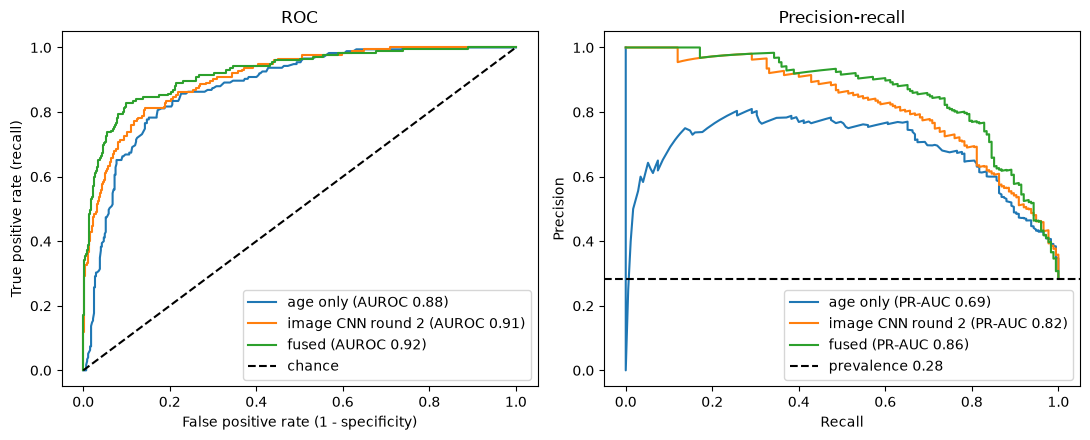

In [3]:
models = {"age only": p_age, "image CNN round 2": p_img, "fused": p_fused}

# Plot ROC and PR curves for all three models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, prob in models.items():
    fpr, tpr, _ = roc_curve(y, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y, prob):.2f})")
    prec, rec, _ = precision_recall_curve(y, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y, prob):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)", title="ROC")
axes[1].axhline(y.mean(), color="k", ls="--", label=f"prevalence {y.mean():.2f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

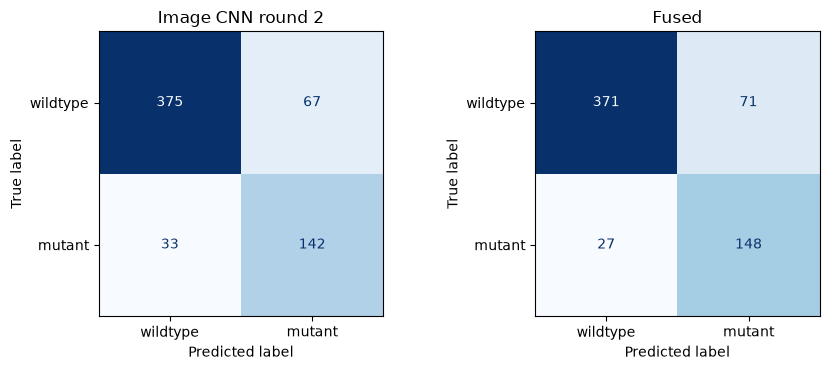

In [4]:
# Plot confusion matrices for the two image CNNs

pred_r2 = threshold_predictions(p_img, y, folds)
pred_fused = threshold_predictions(p_fused, y, folds)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, pred) in zip(axes, {"Image CNN round 2": pred_r2, "Fused": pred_fused}.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["wildtype", "mutant"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

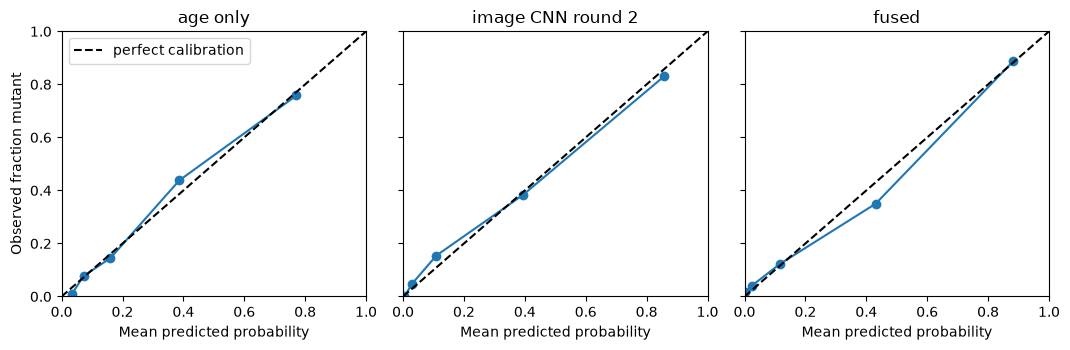

In [5]:
# Plot calibration curves for all three models
fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models), 3.6), sharex=True, sharey=True)
for ax, (name, prob) in zip(axes, models.items()):
    observed, predicted = calibration_curve(y, prob, n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, marker="o")
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.set(xlabel="Mean predicted probability", title=name, xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Observed fraction mutant")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

### Model Comparisons

The primary pre-defined metric is AUROC which the fused model was compared between both age-only and image-only v2. The secondary metrics compared here (exploratory) are PR-AUC and Brier Score. 

Other exploratory analysis: 
- Age-band comparison (just like in `04_cnn_model.ipynb`)
- 50/50 average model: instead of retraining a CNN given image and tabular features, a 50/50 average takes the probabilities from the age-only model and image-only model and takes an average of their probabilities.Determines whether training age and image jointly improves performance over simply combining two models.  

In [6]:
# Headline Comparisons (AUROC)
compare(y, "fused", p_fused, "age-only", p_age)
compare(y, "fused", p_fused, "image v2", p_img)

AUROC fused minus age-only: +0.042 (95% CI +0.009 to +0.071)
AUROC fused minus image v2: +0.015 (95% CI -0.004 to +0.033)


In [8]:
# Exploratory Comparisons (PR-AUC and Brier) between fused and image CNN v2
compare(y, "fused", p_fused, "image v2", p_img, metric=average_precision_score, metric_name="PR-AUC")
compare(y, "fused", p_fused, "image v2", p_img, metric=brier_score_loss, metric_name="Brier ")

PR-AUC fused minus image v2: +0.038 (95% CI +0.001 to +0.077)
Brier  fused minus image v2: -0.014 (95% CI -0.026 to -0.003)


In [10]:
p_avg = 0.5 * p_age + 0.5 * p_img
pred_avg = score_model("avg_age_image_v2", p_avg, y, folds, save=False)   # save=False: not a real model
compare(y, "fused", p_fused, "50/50 average", p_avg)
compare(y, "50/50 average", p_avg, "image v2", p_img)

model           avg_age_image_v2
n_patients               617.000
auroc                      0.929
pr_auc                     0.862
brier                      0.096
accuracy                   0.835
precision                  0.659
recall                     0.863
specificity                0.824
auroc_ci_low               0.907
auroc_ci_high              0.950
pr_auc_ci_low              0.818
pr_auc_ci_high             0.902
per-fold AUROC: [0.892 0.948 0.974 0.883 0.95 ]
AUROC fused minus 50/50 average: -0.006 (95% CI -0.028 to +0.013)
AUROC 50/50 average minus image v2: +0.021 (95% CI +0.006 to +0.040)


In [ ]:
# Bootstrap AUROC by age band
def auroc_or_nan(y_, p_):
    return roc_auc_score(y_, p_) if len(np.unique(y_)) == 2 else np.nan   # resample with one class -> skip

ages = oof[["patient_id"]].merge(cohort[["patient_id", "age"]], on="patient_id", how="left")["age"].to_numpy()
assert not np.isnan(ages).any()
bands = pd.qcut(ages, 3, labels=["youngest third", "middle third", "oldest third"])

rows = []
for band in bands.categories:
    m = np.asarray(bands == band)
    row = {"age band": band, "ages": f"{ages[m].min():.0f} to {ages[m].max():.0f}",
           "n": int(m.sum()), "mutants": int(y[m].sum())}
    for name, prob in {"age only": p_age, "image CNN round 2": p_img, "fused": p_fused, "50/50 average": p_avg}.items():
        lo, hi = bootstrap_ci(y[m], prob[m], auroc_or_nan)
        row[f"AUROC {name} (95% CI)"] = f"{roc_auc_score(y[m], prob[m]):.2f} ({lo:.2f} to {hi:.2f})"
    rows.append(row)
pd.DataFrame(rows).set_index("age band")

,ages,n,mutants,AUROC age only (95% CI),AUROC image CNN round 2 (95% CI),AUROC fused (95% CI),AUROC 50/50 average (95% CI)
age band,,,,,,,
youngest third,18 to 50,212,137,0.68 (0.60 to 0.76),0.87 (0.82 to 0.92),0.87 (0.82 to 0.91),0.87 (0.82 to 0.92)
middle third,51 to 65,215,35,0.60 (0.49 to 0.71),0.82 (0.75 to 0.88),0.85 (0.78 to 0.92),0.80 (0.71 to 0.87)
oldest third,66 to 85,190,3,0.81 (0.61 to 0.94),0.84 (0.58 to 1.00),0.92 (0.86 to 1.00),0.84 (0.57 to 1.00)


### Loss Curve

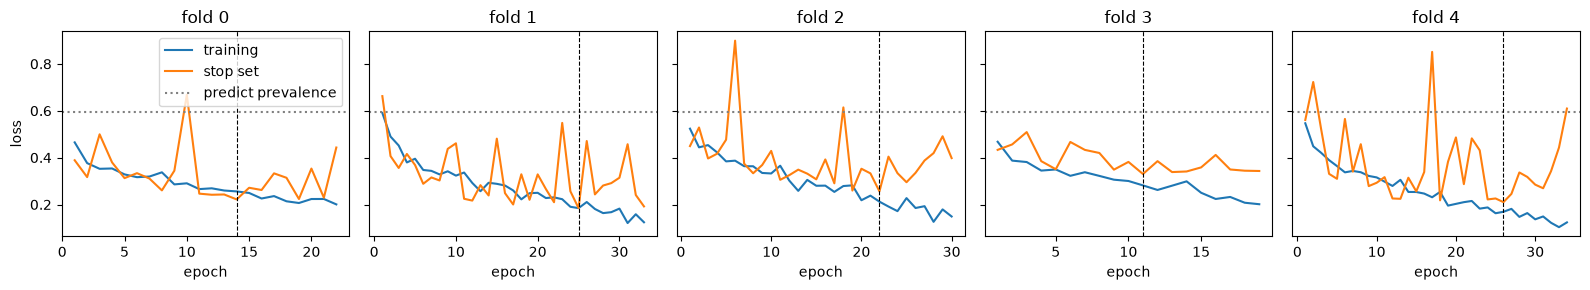

In [11]:
def plot_loss_curves(run_dir):
    h = pd.read_csv(run_dir / "history.csv")
    runs = pd.read_csv(run_dir / "runs.csv")
    if "mode" in h.columns:                       # image-only folders also hold tuning (dev) runs
        h, runs = h[h["mode"] == "final"], runs[runs["mode"] == "final"]
    best = runs.set_index("fold")["best_epoch"]
    m = y.mean()
    prevalence_loss = -(m * np.log(m) + (1 - m) * np.log(1 - m))    # loss of always predicting the mutant rate
    groups = list(h.groupby("fold"))
    fig, axes = plt.subplots(1, len(groups), figsize=(3.2 * len(groups), 3), sharey=True, squeeze=False)
    for ax, (fold, g) in zip(axes[0], groups):
        ax.plot(g["epoch"], g["train_loss"], label="training")
        ax.plot(g["epoch"], g["stop_loss"], label="stop set")
        ax.axhline(prevalence_loss, color="gray", ls=":", label="predict prevalence")
        ax.axvline(best[fold], color="k", ls="--", lw=0.8)     # epoch whose weights were kept
        ax.set(title=f"fold {fold}", xlabel="epoch")
    axes[0][0].set_ylabel("loss")
    axes[0][0].legend()
    plt.tight_layout()
    plt.show()

plot_loss_curves(FUSED_DIR)

## Takeaways

**Primary comparison (AUROC, paired patient-level bootstrap where improvement means 95% CI excludes 0)**
- The fused model reached AUROC 0.922 (95% CI 0.894 to 0.947) on UTSW out-of-fold predictions.
- Fused minus age-only: +0.042 (+0.009 to +0.071). The fused model beats age alone, though the lower end of the interval is close to 0.
- Fused minus image-only (round 2): +0.015 (-0.004 to +0.033). This is **not** deemed an improvement.

**Exploratory (looked at after the pre-specified result; no multiplicity correction)**
- Fused minus image-only: PR-AUC +0.038 (+0.001 to +0.077), Brier -0.014 (-0.026 to -0.003). The Brier difference is the most consistent signal; the PR-AUC interval barely excludes 0.
- A fixed 50/50 average of the age-only and image-only probabilities (nothing fitted) reached AUROC 0.929 (0.907 to 0.950). Fused minus average: -0.006 (-0.028 to +0.013), so end-to-end fusion shows no advantage over simple averaging here. Average minus image-only: +0.021 (+0.006 to +0.040), which is consistent with age and image carrying complementary information.
- Within age bands (about 35 or more mutants in the first two), the image-using models stay well above age-only (youngest third 0.87 for image-only, fused and the 50/50 average vs 0.68; middle third 0.82, 0.85 and 0.80 vs 0.60). The oldest third has 3 mutants and is uninformative. This supports the images carrying information beyond age, but again it does not show what that information is. The 50/50 average is nominally lowest in the middle band, but the intervals overlap and are unpaired, so this is descriptive only.
- At the base-rate cutoff the fused model catches 6 more mutants than image-only (148 vs 142) and calls 4 more wildtype patients mutant (71 vs 67)
- For the fused model, calibration is close to the diagonal, but one middle bin overpredicts, which is within what chance gives with ~123 patients per bin.

**Limitations**
- All UTSW scores are development estimates: the image-only settings were tuned on these patients and the fused model inherits them. Tuning the fused model might worthwhile. Only UCSF is an unbiased test.
- One training run per model, so seed-to-seed variation is unmeasured; the stop-set loss curves are noisy. A difference of 0.015 AUROC is within what retraining could change.
- Intervals cover patient sampling only, not retraining.
- Calibration is internal only.